
Loading master sheet from: Figure1_master.csv
Master sheet columns: ['Video', 'Animal ID', 'Treatment', 'Start Frame', 'PI', 'Time_SC (s)', 'Time_FC (s)', 'Time_SS (s)', 'Time_FS (s)', 'RDI', 'Entries_SC', 'Entries_FC', 'Entries_SS', 'Entries_FS', 'MeanBout_SC (s)', 'MeanBout_FC (s)', 'MeanBout_SS (s)', 'MeanBout_FS (s)', 'MedianBout_SC (s)', 'MedianBout_FC (s)', 'MedianBout_SS (s)', 'MedianBout_FS (s)', 'MaxBout_SC (s)', 'MaxBout_FC (s)', 'MaxBout_SS (s)', 'MaxBout_FS (s)', 'ROIArea_SC (cm2)', 'ROIArea_FC (cm2)', 'ROIArea_SS (cm2)', 'ROIArea_FS (cm2)']
  Treatment columns identified: ['treatment']
Loaded master sheet with 49 entries
Treatment columns found: ['treatment']

Sample treatment entries:
  MVI_0010_roi1: {'treatment': 'GH AL', 'Start Frame': '9830', 'Time_SC (s)': '291.6', 'Time_FC (s)': '221.8', 'Time_SS (s)': '137.64', 'Time_FS (s)': '83.12', 'RDI': '0.25', 'Entries_SC': '24', 'Entries_FC': '23', 'Entries_SS': '52', 'Entries_FS': '40', 'MeanBout_SC (s)': '12.178', 'MeanBo

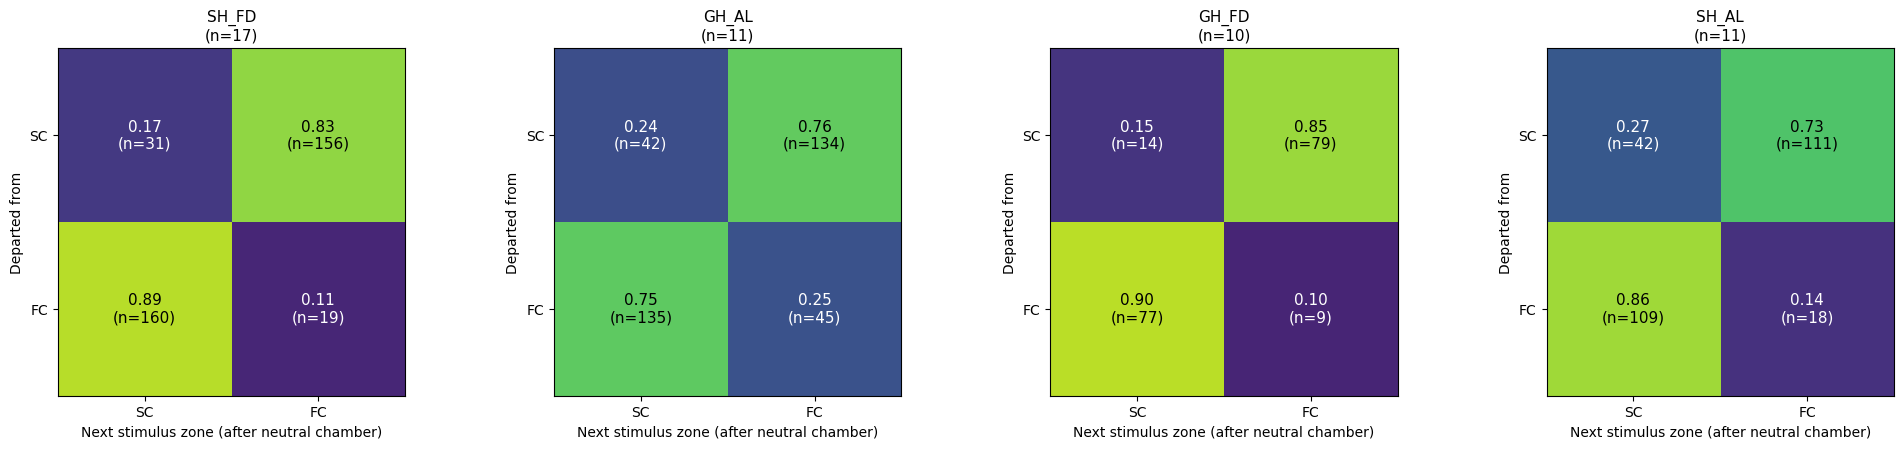

In [18]:
"""
Transition Probability Analysis for SC/FC/Neutral behavior
Designed for Jupyter Notebook execution

STATE DEFINITION:
    - 'SC'      : in_SC == 1
    - 'FC'      : in_FC == 1  (and not in_SC)
    - 'Neutral' : everything else (neutral chamber, or inside FC/SC chamber
                  but not within the stimulus zone)
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

# Set up plotting
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
%matplotlib inline

# ============================================================================
# CONFIGURATION - EDIT THESE PATHS
# ============================================================================

# Path to your CSV files (can be a single file or directory)
INPUT_PATH = "all_augmented_csv/results_with_vertices/with_vertice_labels"  # e.g., "data/behavior/"
# INPUT_PATH = "path/to/single/file.csv"  # or a single file

# Path to master sheet with treatment information (optional but recommended)
MASTER_SHEET_PATH = "Figure1_master.csv"  # Set to None if not using

# Path to start frames file (optional)
START_FRAMES_PATH = None  # Set to "path/to/start_frames.xlsx" if needed

# Output directory
OUTPUT_DIR = "transition_results/"

# Group by column in master sheet
GROUP_BY = "Treatment"  # e.g., "Treatment", "Housing", "Food", or "Combined"

# Number of frames to analyze after start frame
N_FRAMES_WINDOW = 15000

STATES = ["SC", "FC", "Neutral"]

def load_start_frames(file_path):
    """Load start frames from Excel or CSV file."""
    file_path = Path(file_path)
    
    if file_path.suffix.lower() in ['.xlsx', '.xls']:
        df = pd.read_excel(file_path)
    else:
        df = pd.read_csv(file_path)
    
    df.columns = [str(c).strip() for c in df.columns]
    pairs = []
    for _, row in df.iterrows():
        movie = str(row["Movie"]).strip()
        try:
            start = int(row["Start"])
        except (ValueError, TypeError):
            continue
        pairs.append((movie, start))
    return pairs

def load_master_sheet(file_path):
    """Load master sheet CSV with treatment information."""
    df = pd.read_csv(file_path)
    df.columns = [str(c).strip() for c in df.columns]
    
    print(f"Master sheet columns: {list(df.columns)}")
    
    # Try to identify video column
    video_col = None
    for col in df.columns:
        col_lower = col.lower()
        if 'video' in col_lower or 'file' in col_lower or 'movie' in col_lower or 'roi' in col_lower:
            video_col = col
            break
    
    if video_col is None:
        video_col = df.columns[0]
        print(f"  Using '{video_col}' as video/file column")
    
    # Find treatment columns (look for common names)
    treatment_cols = {}
    for col in df.columns:
        col_lower = col.lower()
        if 'treatment' in col_lower:
            treatment_cols['treatment'] = col
        elif 'housing' in col_lower:
            treatment_cols['housing'] = col
        elif 'food' in col_lower:
            treatment_cols['food'] = col
    
    # If no treatment columns found, look for columns that might contain treatment info
    if not treatment_cols:
        potential_treat_cols = []
        for col in df.columns:
            if col != video_col:
                n_unique = df[col].nunique()
                if n_unique <= 10:
                    potential_treat_cols.append(col)
        
        if potential_treat_cols:
            print(f"  Found potential treatment columns: {potential_treat_cols}")
            for i, col in enumerate(potential_treat_cols[:3]):
                if i == 0:
                    treatment_cols['treatment'] = col
                elif i == 1:
                    treatment_cols['housing'] = col
                elif i == 2:
                    treatment_cols['food'] = col
    
    print(f"  Treatment columns identified: {list(treatment_cols.keys())}")
    
    # Build mapping
    treatment_map = {}
    for _, row in df.iterrows():
        video_name = str(row[video_col]).strip()
        treatments = {}
        for key, col in treatment_cols.items():
            val = str(row[col]).strip() if pd.notna(row[col]) else ""
            treatments[key] = val
        
        # Add all other columns as additional info
        for col in df.columns:
            if col != video_col and col not in treatment_cols.values():
                val = str(row[col]).strip() if pd.notna(row[col]) else ""
                if val:
                    treatments[col] = val
        
        treatment_map[video_name] = treatments
    
    return treatment_map, treatment_cols

def match_start_frame(csv_path, start_frame_pairs):
    """Match CSV file to start frame entry."""
    name = csv_path.name.lower()
    candidates = [(m, s) for m, s in start_frame_pairs if m.lower() in name]
    if not candidates:
        return None
    candidates.sort(key=lambda x: len(x[0]), reverse=True)
    return candidates[0]

def match_treatment(csv_path, treatment_map):
    """Match CSV file to treatment information."""
    name = csv_path.name.lower()
    
    for video_name, treatments in treatment_map.items():
        video_name_lower = video_name.lower()
        if video_name_lower in name or name in video_name_lower:
            return treatments
    
    name_parts = name.replace('.csv', '').split('_')
    for video_name, treatments in treatment_map.items():
        video_name_lower = video_name.lower()
        for part in name_parts:
            if part and part in video_name_lower:
                return treatments
    
    return None

def assign_state(df):
    """
    Assign state to each frame.
    
    MODIFIED: Neutral = ONLY in middle chamber (NOT in SC AND NOT in FC)
    Being in SC but not in SC is NOT Neutral (it's considered SC-adjacent or chamber)
    Being in FC but not in FC is NOT Neutral (it's considered FC-adjacent or chamber)
    """
    # Get stimulus zone indicators
    in_ss = pd.to_numeric(df["in_SC"], errors="coerce").fillna(0).astype(int)
    in_fs = pd.to_numeric(df["in_FC"], errors="coerce").fillna(0).astype(int)
    
    # Get chamber indicators (these columns should exist in your data)
    # If they don't exist, we need to create them from ROIArea or other columns
    if "in_SC" in df.columns:
        in_sc = pd.to_numeric(df["in_SC"], errors="coerce").fillna(0).astype(int)
    else:
        # If in_SC doesn't exist, check if we can determine from ROI areas
        # For now, assume if in_SC=0 and in neutral chamber, it's not in SC
        print("  Warning: 'in_SC' column not found. Using alternative method.")
        # Try to determine from ROIArea or other columns
        if "ROIArea_SC" in df.columns:
            # If ROIArea_SC > 0 means in SC chamber
            in_sc = (pd.to_numeric(df["ROIArea_SC"], errors="coerce").fillna(0) > 0).astype(int)
        else:
            # If we can't determine, use a placeholder
            print("  Error: Cannot determine SC chamber presence. Please add 'in_SC' column.")
            in_sc = np.zeros(len(df), dtype=int)
    
    if "in_FC" in df.columns:
        in_fc = pd.to_numeric(df["in_FC"], errors="coerce").fillna(0).astype(int)
    else:
        if "ROIArea_FC" in df.columns:
            in_fc = (pd.to_numeric(df["ROIArea_FC"], errors="coerce").fillna(0) > 0).astype(int)
        else:
            print("  Error: Cannot determine FC chamber presence. Please add 'in_FC' column.")
            in_fc = np.zeros(len(df), dtype=int)
    
    # State assignment with new definition:
    # Neutral = ONLY in chamber (NOT in SC AND NOT in FC)
    # SC = in_SC == 1 (priority over everything else)
    # FC = in_FC == 1 (priority over neutral, but not over SC)
    
    state = []
    for i in range(len(df)):
        if in_ss[i] == 1:
            state.append("SC")
        elif in_fs[i] == 1:
            state.append("FC")
        elif in_sc[i] == 0 and in_fc[i] == 0:
            # ONLY in neutral chamber 
            state.append("Neutral")
        else:
            # In a chamber but not at stimulus zone - we treat this as 
            # "chamber" state which is distinct from Neutral
            # For our purposes, we don't count this as Neutral
            # We'll keep it as "Chamber" but for transition analysis,
            # we need to decide how to handle it.
            # Option 1: Ignore (skip these frames)
            # Option 2: Treat as the same as the nearest stimulus zone
            # Option 3: Create a separate state
            
            # For now, we'll treat it as "Neutral-adjacent" but not count it
            # Actually, let's treat it as part of the chamber's stimulus zone
            # This preserves the animal's location context
            if in_sc[i] == 1:
                # In SC but not at SC - treat as SC-adjacent
                # We'll keep it as SC for transition purposes
                state.append("SC")
            elif in_fc[i] == 1:
                # In FC but not at FC - treat as FC-adjacent
                state.append("FC")
            else:
                state.append("Neutral")
    
    return pd.Series(state, index=df.index)

def collapse_changepoints(state):
    """Collapse consecutive identical states into a single ordered visit sequence."""
    vals = state.values
    seq = [vals[0]]
    for v in vals[1:]:
        if v != seq[-1]:
            seq.append(v)
    return seq

def transition_matrix(seq):
    """Row-normalized transition probability matrix over change-point events."""
    idx = {s: i for i, s in enumerate(STATES)}
    counts = np.zeros((len(STATES), len(STATES)), dtype=int)
    for a, b in zip(seq[:-1], seq[1:]):
        counts[idx[a], idx[b]] += 1
    row_sums = counts.sum(axis=1, keepdims=True)
    probs = np.divide(counts, row_sums, out=np.zeros_like(counts, dtype=float), where=row_sums != 0)
    return counts, probs

def two_step_through_neutral(seq):
    """Count X -> Neutral -> Y patterns where Neutral chamber = only."""
    patterns = {}
    for i in range(1, len(seq) - 1):
        if seq[i] == "Neutral":
            prev_s, next_s = seq[i - 1], seq[i + 1]
            # Only count if prev and next are stimulus zones
            if prev_s in ["SC", "FC"] and next_s in ["SC", "FC"]:
                key = (prev_s, next_s)
                patterns[key] = patterns.get(key, 0) + 1
    return patterns

def two_step_transition_matrix(patterns):
    """Build 2x2 matrix from X -> Neutral -> Y patterns."""
    stim_states = ["SC", "FC"]
    idx = {s: i for i, s in enumerate(stim_states)}
    counts = np.zeros((2, 2), dtype=int)
    for (a, b), c in patterns.items():
        if a in idx and b in idx:
            counts[idx[a], idx[b]] += c
    row_sums = counts.sum(axis=1, keepdims=True)
    probs = np.divide(counts, row_sums, out=np.zeros_like(counts, dtype=float), where=row_sums != 0)
    return stim_states, counts, probs

def process_file(csv_path, start_frame_pairs=None, n_frames_window=15000, treatment_info=None):
    """Process a single CSV file and return transition data."""
    print(f"Processing: {csv_path.name}")
    df = pd.read_csv(csv_path, low_memory=False)
    
    frame_note = "full file"
    if start_frame_pairs is not None:
        match = match_start_frame(csv_path, start_frame_pairs)
        if match is None:
            print(f"  [warning] No matching start frame for {csv_path.name}, using full file")
        else:
            movie_code, start = match
            end = start + n_frames_window
            if start < len(df):
                df = df.iloc[start:end].reset_index(drop=True)
                frame_note = f"frames {start}-{min(end, len(df))} (matched '{movie_code}')"
            else:
                print(f"  [warning] Start frame {start} beyond file length {len(df)}")
    
    # Check for required columns
    required_cols = ["in_SC", "in_FC"]
    for col in required_cols:
        if col not in df.columns:
            print(f"  [error] Column '{col}' not found in {csv_path.name}")
            return None
    
    # Check for chamber columns (needed for new Neutral definition)
    if "in_SC" not in df.columns and "ROIArea_SC" not in df.columns:
        print(f"  [warning] Neither 'in_SC' nor 'ROIArea_SC' found. Neutral definition may be inaccurate.")
    if "in_FC" not in df.columns and "ROIArea_FC" not in df.columns:
        print(f"  [warning] Neither 'in_FC' nor 'ROIArea_FC' found. Neutral definition may be inaccurate.")
    
    state = assign_state(df)
    seq = collapse_changepoints(state)
    n_visits = len(seq)
    n_transitions = n_visits - 1
    print(f"  {frame_note} | {len(df)} frames -> {n_visits} zone visits ({n_transitions} transitions)")
    
    # Count how many Neutral visits (neutral chamber visits)
    n_neutral_visits = sum(1 for s in seq if s == "Neutral")
    print(f"  Neutral chamber visits: {n_neutral_visits}")
    
    counts, probs = transition_matrix(seq)
    patterns = two_step_through_neutral(seq)
    
    # Extract specific transition counts for summary CSV
    # First-order transitions (from each state to Neutral)
    trans_counts = {
        'SC_to_Neutral': 0,
        'FC_to_Neutral': 0,
        'Neutral_to_SC': 0,
        'Neutral_to_FC': 0
    }
    
    # Count first-order transitions from the sequence
    for i in range(len(seq) - 1):
        if seq[i] == 'SC' and seq[i+1] == 'Neutral':
            trans_counts['SC_to_Neutral'] += 1
        elif seq[i] == 'FC' and seq[i+1] == 'Neutral':
            trans_counts['FC_to_Neutral'] += 1
        elif seq[i] == 'Neutral' and seq[i+1] == 'SC':
            trans_counts['Neutral_to_SC'] += 1
        elif seq[i] == 'Neutral' and seq[i+1] == 'FC':
            trans_counts['Neutral_to_FC'] += 1
    
    # Second-order transitions (via Neutral)
    second_order = {
        'SC_Neutral_SC': patterns.get(('SC', 'SC'), 0),
        'SC_Neutral_FC': patterns.get(('SC', 'FC'), 0),
        'FC_Neutral_SC': patterns.get(('FC', 'SC'), 0),
        'FC_Neutral_FC': patterns.get(('FC', 'FC'), 0)
    }
    
    return {
        'seq': seq,
        'counts': counts,
        'probs': probs,
        'patterns': patterns,
        'treatment': treatment_info,
        'name': csv_path.stem,
        'n_visits': n_visits,
        'n_transitions': n_transitions,
        'n_neutral_visits': n_neutral_visits,
        'trans_counts': trans_counts,
        'second_order': second_order
    }

def plot_transition_matrix(probs, counts, title, ax=None):
    """Plot 3x3 transition matrix."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    
    im = ax.imshow(probs, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(STATES)))
    ax.set_yticks(range(len(STATES)))
    ax.set_xticklabels(STATES)
    ax.set_yticklabels(STATES)
    ax.set_xlabel("To")
    ax.set_ylabel("From")
    ax.set_title(title, fontsize=11)
    
    for i in range(len(STATES)):
        for j in range(len(STATES)):
            if i == j:
                continue
            txt_color = "white" if probs[i, j] < 0.5 else "black"
            ax.text(j, i, f"{probs[i, j]:.2f}\n(n={counts[i, j]})",
                    ha="center", va="center", color=txt_color, fontsize=10)
    
    return im

def plot_switch_matrix(probs, counts, title, ax=None):
    """Plot 2x2 SC/FC switch matrix."""
    stim_states = ["SC", "FC"]
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4.5))
    
    im = ax.imshow(probs, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(stim_states)))
    ax.set_yticks(range(len(stim_states)))
    ax.set_xticklabels(stim_states)
    ax.set_yticklabels(stim_states)
    ax.set_xlabel("Next stimulus zone (after neutral chamber)")
    ax.set_ylabel("Departed from")
    ax.set_title(title, fontsize=11)
    
    for i in range(len(stim_states)):
        for j in range(len(stim_states)):
            txt_color = "white" if probs[i, j] < 0.5 else "black"
            ax.text(j, i, f"{probs[i, j]:.2f}\n(n={counts[i, j]})",
                    ha="center", va="center", color=txt_color, fontsize=11)
    
    return im

def merge_by_group(all_data, group_key="Treatment"):
    """Merge transition data by treatment group."""
    group_data = defaultdict(lambda: {
        'data': [],
        'total_counts': np.zeros((len(STATES), len(STATES)), dtype=int),
        'two_step_patterns': defaultdict(int),
        'total_visits': 0,
        'total_transitions': 0,
        'total_neutral_visits': 0,
        'total_trans_counts': defaultdict(int),
        'total_second_order': defaultdict(int)
    })
    
    for result in all_data:
        if result is None or result['treatment'] is None:
            continue
        
        # Extract group key
        if group_key == "Combined":
            key_parts = []
            for k, v in sorted(result['treatment'].items()):
                if v and k not in ['Animal ID', 'Video', 'File']:
                    key_parts.append(f"{k}:{v}")
            key = "_".join(key_parts) if key_parts else "Unknown"
        else:
            if group_key in result['treatment']:
                key = result['treatment'][group_key]
            else:
                key = "Unknown"
                for k, v in result['treatment'].items():
                    if k.lower() == group_key.lower():
                        key = v
                        break
                if key == "Unknown":
                    print(f"  [warning] Group key '{group_key}' not found in {result['name']}, using 'Unknown'")
        
        group_data[key]['data'].append(result)
        group_data[key]['total_counts'] += result['counts']
        group_data[key]['total_visits'] += result['n_visits']
        group_data[key]['total_transitions'] += result['n_transitions']
        group_data[key]['total_neutral_visits'] += result.get('n_neutral_visits', 0)
        
        # Add first-order transitions
        for key_name, value in result['trans_counts'].items():
            group_data[key]['total_trans_counts'][key_name] += value
        
        # Add second-order transitions
        for key_name, value in result['second_order'].items():
            group_data[key]['total_second_order'][key_name] += value
        
        for (a, b), c in result['patterns'].items():
            if a in ['SC', 'FC'] and b in ['SC', 'FC']:
                group_data[key]['two_step_patterns'][(a, b)] += c
    
    # Calculate merged probabilities
    results = {}
    stim_states = ["SC", "FC"]
    idx = {s: i for i, s in enumerate(stim_states)}
    
    for group, data in group_data.items():
        # Normalize transition matrix
        row_sums = data['total_counts'].sum(axis=1, keepdims=True)
        probs = np.divide(data['total_counts'], row_sums, 
                         out=np.zeros_like(data['total_counts'], dtype=float), 
                         where=row_sums != 0)
        
        # Normalize two-step matrix
        two_step_counts = np.zeros((2, 2), dtype=int)
        for (a, b), c in data['two_step_patterns'].items():
            if a in idx and b in idx:
                two_step_counts[idx[a], idx[b]] += c
        
        row_sums_2 = two_step_counts.sum(axis=1, keepdims=True)
        two_step_probs = np.divide(two_step_counts, row_sums_2,
                                  out=np.zeros_like(two_step_counts, dtype=float),
                                  where=row_sums_2 != 0)
        
        results[group] = {
            'files': [d['name'] for d in data['data']],
            'total_visits': data['total_visits'],
            'total_transitions': data['total_transitions'],
            'total_neutral_visits': data['total_neutral_visits'],
            'transition_counts': data['total_counts'],
            'transition_probs': probs,
            'two_step_counts': two_step_counts,
            'two_step_probs': two_step_probs,
            'two_step_patterns': dict(data['two_step_patterns']),
            'trans_counts': dict(data['total_trans_counts']),
            'second_order': dict(data['total_second_order'])
        }
    
    return results

def save_results(all_data, merged_results, output_dir):
    """Save all results to CSV files."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    
    # Save individual file results
    for result in all_data:
        if result is None:
            continue
        
        # Save transition matrix
        mat_df = pd.DataFrame(result['probs'], 
                             index=[f"from_{s}" for s in STATES], 
                             columns=[f"to_{s}" for s in STATES])
        cnt_df = pd.DataFrame(result['counts'], 
                             index=[f"from_{s}" for s in STATES], 
                             columns=[f"to_{s}" for s in STATES])
        
        csv_out = output_dir / f"{result['name']}_transition_probs.csv"
        with open(csv_out, "w") as f:
            f.write("# Transition probabilities (row-normalized, change-point events only)\n")
            f.write("# Neutral = ONLY in neutral chamber (NOT in SC and NOT in FC)\n\n")
            mat_df.to_csv(f)
            f.write("\n# Raw transition counts\n")
            cnt_df.to_csv(f)
        
        # Save switch matrix
        stim_states = ["SC", "FC"]
        sw_counts, sw_probs = two_step_transition_matrix(result['patterns'])[1:]
        sw_mat_df = pd.DataFrame(sw_probs, 
                                index=[f"from_{s}" for s in stim_states],
                                columns=[f"to_{s}" for s in stim_states])
        sw_cnt_df = pd.DataFrame(sw_counts, 
                                index=[f"from_{s}" for s in stim_states],
                                columns=[f"to_{s}" for s in stim_states])
        
        sw_csv_out = output_dir / f"{result['name']}_SC_FC_switch_probs.csv"
        with open(sw_csv_out, "w") as f:
            f.write("# SC/FC switch-vs-return probabilities (via neutral chamber only)\n")
            sw_mat_df.to_csv(f)
            f.write("\n# Raw counts\n")
            sw_cnt_df.to_csv(f)
    
    # Save merged results
    for group, result in merged_results.items():
        group_name = str(group).replace(" ", "_").replace("/", "_").replace(":", "_")
        
        # Save transition matrix
        mat_df = pd.DataFrame(result['transition_probs'], 
                             index=[f"from_{s}" for s in STATES], 
                             columns=[f"to_{s}" for s in STATES])
        cnt_df = pd.DataFrame(result['transition_counts'], 
                             index=[f"from_{s}" for s in STATES], 
                             columns=[f"to_{s}" for s in STATES])
        
        csv_out = output_dir / f"merged_{group_name}_transition_probs.csv"
        with open(csv_out, "w") as f:
            f.write(f"# Merged transition probabilities for group: {group}\n")
            f.write(f"# Files: {', '.join(result['files'])}\n")
            f.write(f"# Total visits: {result['total_visits']}, Total transitions: {result['total_transitions']}\n")
            f.write(f"# Total neutral chamber visits: {result['total_neutral_visits']}\n")
            f.write("# Neutral = ONLY in neutral chamber (NOT in SC and NOT in FC)\n\n")
            mat_df.to_csv(f)
            f.write("\n# Raw transition counts\n")
            cnt_df.to_csv(f)
        
        # Save switch matrix
        sw_mat_df = pd.DataFrame(result['two_step_probs'], 
                                index=[f"from_{s}" for s in ["SC", "FC"]],
                                columns=[f"to_{s}" for s in ["SC", "FC"]])
        sw_cnt_df = pd.DataFrame(result['two_step_counts'], 
                                index=[f"from_{s}" for s in ["SC", "FC"]],
                                columns=[f"to_{s}" for s in ["SC", "FC"]])
        
        sw_csv_out = output_dir / f"merged_{group_name}_SC_FC_switch_probs.csv"
        with open(sw_csv_out, "w") as f:
            f.write(f"# Merged SC/FC switch probabilities for group: {group}\n")
            f.write(f"# Files: {', '.join(result['files'])}\n")
            f.write(f"# Total visits: {result['total_visits']}, Total transitions: {result['total_transitions']}\n")
            f.write("# Neutral = ONLY in neutral chamber (NOT in SC and NOT in FC)\n\n")
            sw_mat_df.to_csv(f)
            f.write("\n# Raw counts\n")
            sw_cnt_df.to_csv(f)
    
    # NEW: Save per-video summary CSV with all transition counts
    save_per_video_summary(all_data, output_dir)

def save_per_video_summary(all_data, output_dir):
    """Save a CSV with per-video transition counts including first and second order."""
    rows = []
    
    for result in all_data:
        if result is None:
            continue
        
        # Get treatment information
        treatment_str = ""
        if result['treatment']:
            treatment_parts = []
            for key, value in sorted(result['treatment'].items()):
                if value:
                    treatment_parts.append(f"{key}:{value}")
            treatment_str = " | ".join(treatment_parts)
        
        # Build row dictionary
        row = {
            'Video': result['name'],
            'Treatment': treatment_str,
            'Total_Visits': result['n_visits'],
            'Total_Transitions': result['n_transitions'],
            'Neutral_Visits': result['n_neutral_visits'],
            
            # First-order transitions (to/from Neutral)
            'SC_to_Neutral': result['trans_counts']['SC_to_Neutral'],
            'FC_to_Neutral': result['trans_counts']['FC_to_Neutral'],
            'Neutral_to_SC': result['trans_counts']['Neutral_to_SC'],
            'Neutral_to_FC': result['trans_counts']['Neutral_to_FC'],
            
            # Total transitions involving Neutral (as destination)
            'Total_to_Neutral': result['trans_counts']['SC_to_Neutral'] + result['trans_counts']['FC_to_Neutral'],
            # Total transitions from Neutral (as source)
            'Total_from_Neutral': result['trans_counts']['Neutral_to_SC'] + result['trans_counts']['Neutral_to_FC'],
            
            # Second-order transitions (via Neutral)
            'SC_Neutral_SC': result['second_order']['SC_Neutral_SC'],
            'SC_Neutral_FC': result['second_order']['SC_Neutral_FC'],
            'FC_Neutral_SC': result['second_order']['FC_Neutral_SC'],
            'FC_Neutral_FC': result['second_order']['FC_Neutral_FC'],
            
            # Total second-order transitions via Neutral
            'Total_Neutral_mediated': sum(result['second_order'].values()),
            
            # Switch vs Return (via Neutral)
            'Switch_via_Neutral': result['second_order']['SC_Neutral_FC'] + result['second_order']['FC_Neutral_SC'],
            'Return_via_Neutral': result['second_order']['SC_Neutral_SC'] + result['second_order']['FC_Neutral_FC'],
        }
        
        # Calculate switch probability if possible
        total_mediated = row['Total_Neutral_mediated']
        if total_mediated > 0:
            row['Switch_Probability'] = row['Switch_via_Neutral'] / total_mediated
        else:
            row['Switch_Probability'] = np.nan
        
        rows.append(row)
    
    # Create DataFrame and save
    df_summary = pd.DataFrame(rows)
    
    # Reorder columns for better readability
    column_order = [
        'Video', 'Treatment',
        'Total_Visits', 'Total_Transitions', 'Neutral_Visits',
        'SC_to_Neutral', 'FC_to_Neutral', 'Neutral_to_SC', 'Neutral_to_FC',
        'Total_to_Neutral', 'Total_from_Neutral',
        'SC_Neutral_SC', 'SC_Neutral_FC', 'FC_Neutral_SC', 'FC_Neutral_FC',
        'Total_Neutral_mediated', 'Switch_via_Neutral', 'Return_via_Neutral', 'Switch_Probability'
    ]
    
    # Only keep columns that exist
    existing_columns = [col for col in column_order if col in df_summary.columns]
    df_summary = df_summary[existing_columns]
    
    # Save to CSV
    csv_out = output_dir / "per_video_transition_summary.csv"
    df_summary.to_csv(csv_out, index=False)
    print(f"\nPer-video transition summary saved to: {csv_out}")
    print(f"  Columns: {', '.join(df_summary.columns)}")

def plot_results(all_data, merged_results, output_dir):
    """Generate plots for all results."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    
    # Plot individual files
    for result in all_data:
        if result is None:
            continue
        
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        
        # 3x3 transition matrix
        plot_transition_matrix(result['probs'], result['counts'], 
                              f"{result['name']}\nZone transition probabilities\n(Neutral = neutral chamber only)", axes[0])
        
        # 2x2 switch matrix
        sw_counts, sw_probs = two_step_transition_matrix(result['patterns'])[1:]
        plot_switch_matrix(sw_probs, sw_counts, 
                          f"{result['name']}\nSC/FC switch probabilities\n(via neutral chamber only)", axes[1])
        
        plt.tight_layout()
        plt.savefig(output_dir / f"{result['name']}_matrices.pdf", bbox_inches="tight", dpi=150)
        plt.close()
    
    # Plot merged results
    for group, result in merged_results.items():
        group_name = str(group).replace(" ", "_").replace("/", "_").replace(":", "_")
        
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        
        # 3x3 transition matrix
        plot_transition_matrix(result['transition_probs'], result['transition_counts'], 
                              f"{group_name} (n={len(result['files'])} files)\nZone transition probabilities\n(Neutral = neutral chamber only)", axes[0])
        
        # 2x2 switch matrix
        plot_switch_matrix(result['two_step_probs'], result['two_step_counts'], 
                          f"{group_name} (n={len(result['files'])} files)\nSC/FC switch probabilities\n(via neutral chamber only)", axes[1])
        
        plt.tight_layout()
        plt.savefig(output_dir / f"merged_{group_name}_matrices.pdf", bbox_inches="tight", dpi=150)
        plt.close()
    
    # Create summary comparison plot
    if len(merged_results) > 1:
        fig, axes = plt.subplots(1, len(merged_results), figsize=(6*len(merged_results), 5))
        if len(merged_results) == 1:
            axes = [axes]
        
        for ax, (group, result) in zip(axes, merged_results.items()):
            group_name = str(group).replace(" ", "_").replace("/", "_").replace(":", "_")
            plot_switch_matrix(result['two_step_probs'], result['two_step_counts'],
                              f"{group_name}\n(n={len(result['files'])} files)\n(via neutral chamber only)", ax)
        
        plt.tight_layout()
        plt.savefig(output_dir / "comparison_switch_matrices.pdf", bbox_inches="tight", dpi=150)
        plt.close()

def print_summary(all_data, merged_results):
    """Print summary statistics."""
    print("\n" + "="*60)
    print("SUMMARY")
    print("="*60)
    
    valid_results = [r for r in all_data if r is not None]
    print(f"\nTotal files processed: {len(valid_results)}")
    
    total_neutral_chamber_visits = sum(r.get('n_neutral_visits', 0) for r in valid_results)
    print(f"Total neutral chamber (Neutral) visits: {total_neutral_chamber_visits}")
    
    # Print first-order transition summary
    total_SC_to_Neutral = sum(r['trans_counts']['SC_to_Neutral'] for r in valid_results)
    total_FC_to_Neutral = sum(r['trans_counts']['FC_to_Neutral'] for r in valid_results)
    total_Neutral_to_SC = sum(r['trans_counts']['Neutral_to_SC'] for r in valid_results)
    total_Neutral_to_FC = sum(r['trans_counts']['Neutral_to_FC'] for r in valid_results)
    
    print(f"\nFirst-order transitions (to/from Neutral):")
    print(f"  SC -> Neutral: {total_SC_to_Neutral}")
    print(f"  FC -> Neutral: {total_FC_to_Neutral}")
    print(f"  Neutral -> SC: {total_Neutral_to_SC}")
    print(f"  Neutral -> FC: {total_Neutral_to_FC}")
    
    # Print second-order transition summary
    total_SC_Neutral_SC = sum(r['second_order']['SC_Neutral_SC'] for r in valid_results)
    total_SC_Neutral_FC = sum(r['second_order']['SC_Neutral_FC'] for r in valid_results)
    total_FC_Neutral_SC = sum(r['second_order']['FC_Neutral_SC'] for r in valid_results)
    total_FC_Neutral_FC = sum(r['second_order']['FC_Neutral_FC'] for r in valid_results)
    
    print(f"\nSecond-order transitions (via Neutral):")
    print(f"  SC -> Neutral -> SC (return): {total_SC_Neutral_SC}")
    print(f"  SC -> Neutral -> FC (switch): {total_SC_Neutral_FC}")
    print(f"  FC -> Neutral -> SC (switch): {total_FC_Neutral_SC}")
    print(f"  FC -> Neutral -> FC (return): {total_FC_Neutral_FC}")
    
    total_switches = total_SC_Neutral_FC + total_FC_Neutral_SC
    total_mediated = total_SC_Neutral_SC + total_SC_Neutral_FC + total_FC_Neutral_SC + total_FC_Neutral_FC
    if total_mediated > 0:
        print(f"\nOverall switch probability (via Neutral): {total_switches / total_mediated:.3f}")
    
    if merged_results:
        print("\nMerged groups:")
        for group, result in merged_results.items():
            print(f"\n  {group}:")
            print(f"    Files: {len(result['files'])}")
            print(f"    Total visits: {result['total_visits']}")
            print(f"    Total transitions: {result['total_transitions']}")
            print(f"    Total neutral chamber visits: {result['total_neutral_visits']}")
            
            # Show switch probabilities
            total_switches = result['two_step_counts'][0, 1] + result['two_step_counts'][1, 0]
            total_transitions = result['two_step_counts'].sum()
            
            print(f"    SC -> Corridor -> FC: {result['two_step_counts'][0, 1]} ({result['two_step_probs'][0, 1]:.3f})")
            print(f"    FC -> Corridor -> SC: {result['two_step_counts'][1, 0]} ({result['two_step_probs'][1, 0]:.3f})")
            print(f"    SC -> Corridor -> SC (returned): {result['two_step_counts'][0, 0]} ({result['two_step_probs'][0, 0]:.3f})")
            print(f"    FC -> Corridor -> FC (returned): {result['two_step_counts'][1, 1]} ({result['two_step_probs'][1, 1]:.3f})")
            
            if total_transitions > 0:
                print(f"    Switch probability: {total_switches / total_transitions:.3f}")
            else:
                print(f"    Switch probability: N/A (no transitions)")
    else:
        print("\nNo merged results (master sheet not provided or no matches)")

# ============================================================================
# MAIN EXECUTION
# ============================================================================

def main():
    """Main execution function."""
    
    # Create output directory
    output_dir = Path(OUTPUT_DIR)
    output_dir.mkdir(parents=True, exist_ok=True)
    
    # Load start frames if provided
    start_frame_pairs = None
    if START_FRAMES_PATH:
        start_frame_pairs = load_start_frames(START_FRAMES_PATH)
        print(f"Loaded {len(start_frame_pairs)} start-frame entries")
    
    # Load master sheet if provided
    treatment_map = None
    if MASTER_SHEET_PATH:
        print(f"\nLoading master sheet from: {MASTER_SHEET_PATH}")
        treatment_map, treatment_cols = load_master_sheet(MASTER_SHEET_PATH)
        print(f"Loaded master sheet with {len(treatment_map)} entries")
        print(f"Treatment columns found: {list(treatment_cols.keys())}")
        
        print("\nSample treatment entries:")
        for i, (video, treatments) in enumerate(list(treatment_map.items())[:3]):
            print(f"  {video}: {treatments}")
        if len(treatment_map) > 3:
            print(f"  ... and {len(treatment_map) - 3} more")
    
    # Get list of CSV files
    input_path = Path(INPUT_PATH)
    if input_path.is_file():
        csv_paths = [input_path]
    else:
        csv_paths = sorted(input_path.glob("*.csv"))
        if not csv_paths:
            csv_paths = sorted(input_path.glob("*.CSV"))
    
    print(f"\nFound {len(csv_paths)} CSV files\n")
    
    # Process each file
    all_data = []
    for csv_path in csv_paths:
        # Get treatment info if master sheet is provided
        treatment_info = None
        if treatment_map:
            treatment_info = match_treatment(csv_path, treatment_map)
            if treatment_info is None:
                print(f"  [warning] No treatment info found for {csv_path.name}")
            else:
                print(f"  Matched '{csv_path.name}' to treatment: {treatment_info}")
        
        result = process_file(csv_path, start_frame_pairs, N_FRAMES_WINDOW, treatment_info)
        if result is not None:
            all_data.append(result)
    
    # Merge by treatment groups if master sheet is provided
    merged_results = {}
    if treatment_map and all_data:
        print("\n" + "="*50)
        print("MERGING DATA BY TREATMENT GROUPS")
        print("="*50)
        print(f"Grouping by: {GROUP_BY}")
        merged_results = merge_by_group(all_data, GROUP_BY)
        
        for group, result in merged_results.items():
            print(f"\nGroup: {group}")
            print(f"  Files: {len(result['files'])}")
            print(f"  Total visits: {result['total_visits']}")
            print(f"  Total transitions: {result['total_transitions']}")
            print(f"  Total neutral chamber visits: {result['total_neutral_visits']}")
    
    # Save results
    print("\n" + "="*50)
    print("SAVING RESULTS")
    print("="*50)
    save_results(all_data, merged_results, output_dir)
    print(f"\nResults saved to: {output_dir}")
    
    # Generate plots
    print("\n" + "="*50)
    print("GENERATING PLOTS")
    print("="*50)
    plot_results(all_data, merged_results, output_dir)
    print(f"Plots saved to: {output_dir}")
    
    # Print summary
    print_summary(all_data, merged_results)
    
    return all_data, merged_results

# ============================================================================
# RUN THE ANALYSIS
# ============================================================================

# Execute the main function
all_results, merged_group_results = main()

# Display some results interactively
if merged_group_results:
    print("\n" + "="*60)
    print("INTERACTIVE DISPLAY - SC/FC SWITCH MATRICES (via neutral chamber only)")
    print("="*60)
    
    n_groups = len(merged_group_results)
    fig, axes = plt.subplots(1, n_groups, figsize=(5*n_groups, 4.5))
    if n_groups == 1:
        axes = [axes]
    
    for ax, (group, result) in zip(axes, merged_group_results.items()):
        group_name = str(group).replace(" ", "_").replace("/", "_").replace(":", "_")
        plot_switch_matrix(result['two_step_probs'], result['two_step_counts'],
                          f"{group_name}\n(n={len(result['files'])})", ax)
    
    plt.tight_layout()
    plt.show()
else:
    # Show individual results if no groups
    if all_results:
        print("\n" + "="*60)
        print("INTERACTIVE DISPLAY - INDIVIDUAL RESULTS (via neutral chamber only)")
        print("="*60)
        
        n_results = len([r for r in all_results if r is not None])
        if n_results > 0:
            fig, axes = plt.subplots(1, min(n_results, 4), figsize=(5*min(n_results, 4), 4.5))
            # Add code to display individual results if needed
            pass

DATA SUMMARY
Group Housing Food  Switch_Prob  Total_Switches  Total_Returns
SH_FD      SH   FD     0.423592             316             50
GH_AL      GH   AL     0.373611             269             87
GH_FD      GH   FD     0.423913             156             23
SH_AL      SH   AL     0.387324             220             60

TEST 1: LOGISTIC REGRESSION (Primary Analysis)
Why: Tests Housing × Food interaction while accounting for sample sizes
Interpretation: Significant interaction = Housing effect depends on Food treatment
----------------------------------------------------------------------

Model 1: Main effects (Housing + Food)
                 Generalized Linear Model Regression Results                  
Dep. Variable:            Prop_Switch   No. Observations:                    4
Model:                            GLM   Df Residuals:                        1
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Sc

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:130: ValueWarning: unknown kwargs ['weights']
  warnings.warn(msg, ValueWarning)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:130: ValueWarning: unknown kwargs ['weights']
  warnings.warn(msg, ValueWarning)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)


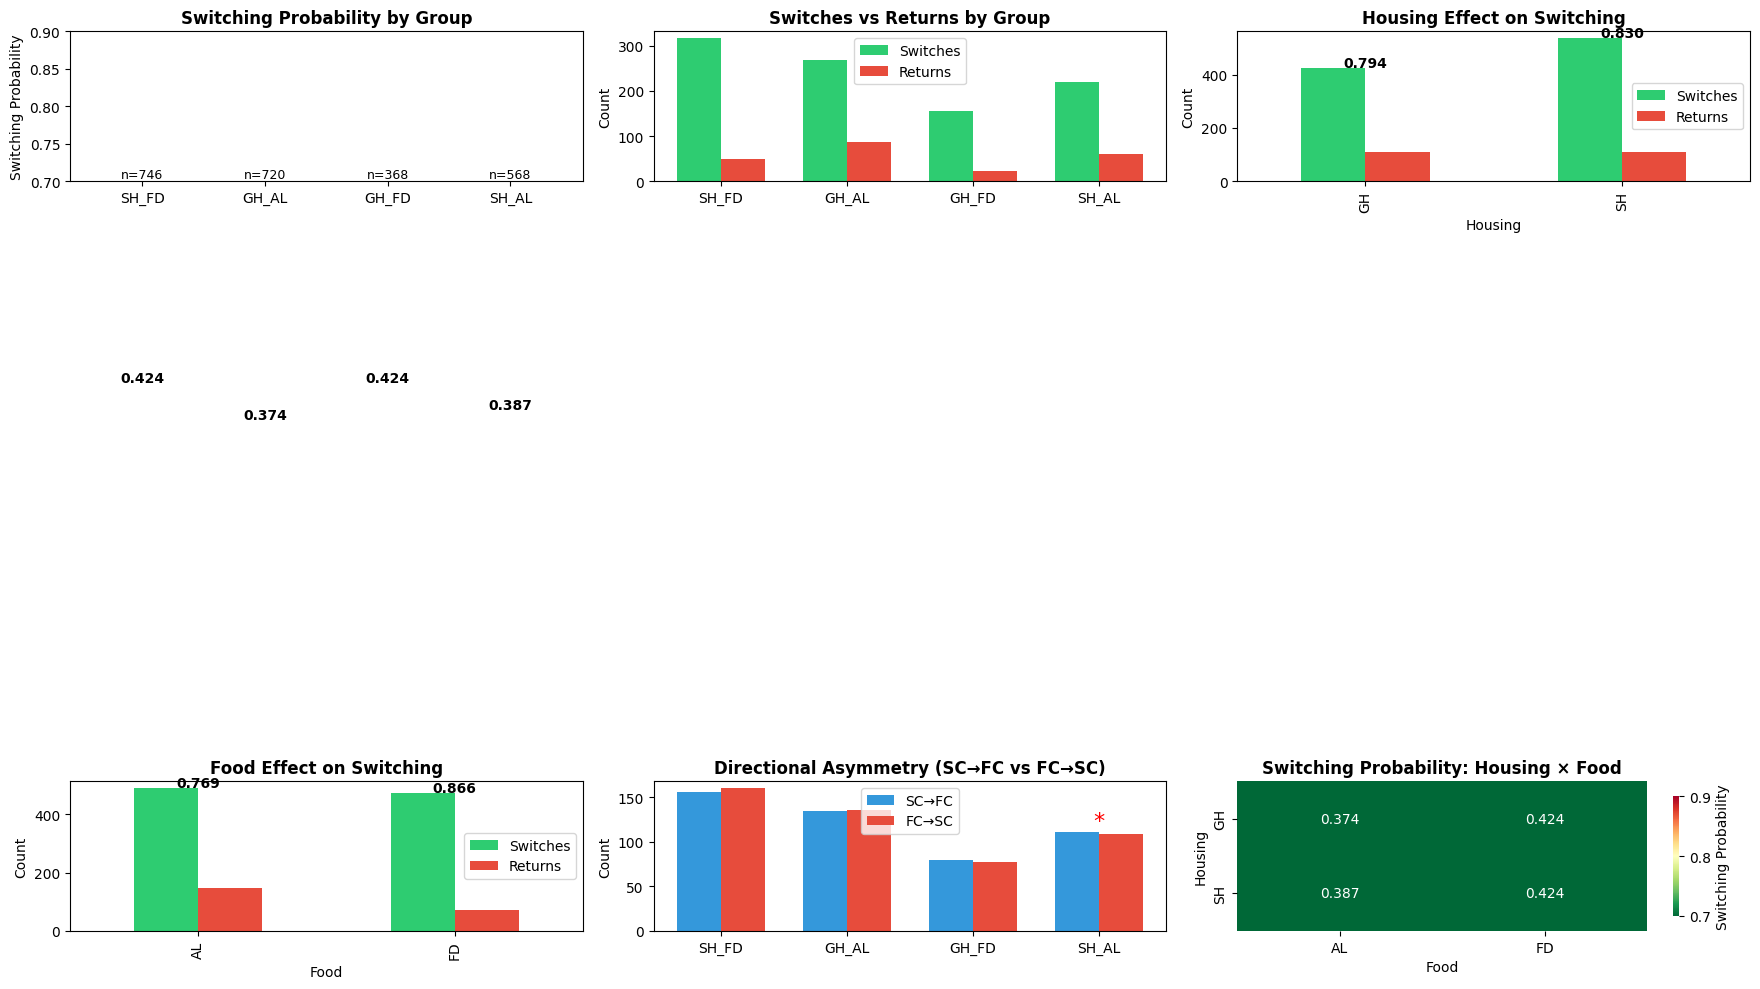


Plot saved as 'statistical_analysis_results.png'

FINAL SUMMARY TABLE
Group Housing Food  Switch_Prob  Return_Prob  Total_Switches  Total_Returns  Transitions
SH_FD      SH   FD        0.424        0.067             316             50          746
GH_AL      GH   AL        0.374        0.121             269             87          720
GH_FD      GH   FD        0.424        0.062             156             23          368
SH_AL      SH   AL        0.387        0.106             220             60          568

STATISTICAL CONCLUSIONS

1. Logistic Regression (Interaction):
   Housing × Food interaction: p = 0.9884 ✗ Not significant
   → The interaction is not significant

2. Main Effects (Chi-square):
   Housing effect: χ² = 2.182, p = 0.1396 (not significant)
   Food effect: χ² = 17.653, p = 0.0000 (significant)

3. Pairwise Comparisons (Bonferroni-corrected):
   2 significant pairwise differences
   SH_FD vs GH_AL, GH_AL vs GH_FD

4. Directional Asymmetry:
   Overall FC→SC vs SC→FC: 

In [15]:
"""
Statistical Analysis for Chamber Transition Data
Tests: Housing × Food interaction on switching probability
"""

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency, fisher_exact
import statsmodels.api as sm
from statsmodels.formula.api import glm
from statsmodels.genmod.families import Binomial
from scipy.stats import chi2 as chi2_dist
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================================
# YOUR DATA
# ============================================================================

data = {
    'Group': ['SH_FD', 'GH_AL', 'GH_FD', 'SH_AL'],
    'Housing': ['SH', 'GH', 'GH', 'SH'],
    'Food': ['FD', 'AL', 'FD', 'AL'],
    'SC_to_FC': [156, 134, 79, 111],
    'SC_to_SC': [31, 42, 14, 42],
    'FC_to_SC': [160, 135, 77, 109],
    'FC_to_FC': [19, 45, 9, 18],
    'Total_visits': [763, 731, 378, 579],
    'Transitions': [746, 720, 368, 568],
    'Neutral_visits': [380, 364, 189, 288]
}

df = pd.DataFrame(data)

# Calculate derived metrics
df['SC_total'] = df['SC_to_FC'] + df['SC_to_SC']
df['FC_total'] = df['FC_to_SC'] + df['FC_to_FC']
df['Total_Switches'] = df['SC_to_FC'] + df['FC_to_SC']
df['Total_Returns'] = df['SC_to_SC'] + df['FC_to_FC']
df['Switch_Prob'] = df['Total_Switches'] / df['Transitions']
df['Return_Prob'] = df['Total_Returns'] / df['Transitions']

print("="*70)
print("DATA SUMMARY")
print("="*70)
print(df[['Group', 'Housing', 'Food', 'Switch_Prob', 'Total_Switches', 'Total_Returns']].to_string(index=False))

# ============================================================================
# TEST 1: LOGISTIC REGRESSION (PRIMARY - RECOMMENDED)
# ============================================================================

print("\n" + "="*70)
print("TEST 1: LOGISTIC REGRESSION (Primary Analysis)")
print("="*70)
print("Why: Tests Housing × Food interaction while accounting for sample sizes")
print("Interpretation: Significant interaction = Housing effect depends on Food treatment")
print("-"*70)

# Prepare data for logistic regression
logit_data = []
for _, row in df.iterrows():
    logit_data.append({
        'Housing': row['Housing'],
        'Food': row['Food'],
        'Group': row['Group'],
        'Switches': row['Total_Switches'],
        'Returns': row['Total_Returns'],
        'Total': row['Transitions'],
        'Prop_Switch': row['Switch_Prob']
    })

logit_df = pd.DataFrame(logit_data)

# Model 1: Main effects only
model1 = glm('Prop_Switch ~ Housing + Food', 
             data=logit_df, 
             family=Binomial(),
             weights=logit_df['Total']).fit()

# Model 2: Interaction
model2 = glm('Prop_Switch ~ Housing * Food', 
             data=logit_df, 
             family=Binomial(),
             weights=logit_df['Total']).fit()

print("\nModel 1: Main effects (Housing + Food)")
print(model1.summary())
print(f"\nAIC: {model1.aic:.2f}")

print("\nModel 2: Interaction (Housing * Food)")
print(model2.summary())
print(f"\nAIC: {model2.aic:.2f}")

# Likelihood ratio test
lr_stat = 2 * (model2.llf - model1.llf)
lr_p = 1 - chi2_dist.cdf(lr_stat, df=1)
print(f"\nLikelihood Ratio Test (Interaction significance):")
print(f"  χ² = {lr_stat:.3f}, df = 1, p = {lr_p:.4f}")
print(f"  {'✓ SIGNIFICANT' if lr_p < 0.05 else '✗ Not significant'} - Interaction term")

# ============================================================================
# TEST 2: CHI-SQUARE TESTS (SECONDARY)
# ============================================================================

print("\n" + "="*70)
print("TEST 2: CHI-SQUARE TESTS (Secondary Analysis)")
print("="*70)
print("Why: Tests if Housing or Food independently affect switching")
print("Interpretation: Significant = treatment affects switching behavior")
print("-"*70)

# 2A: Housing effect (pooling across food treatments)
print("\n2A. Housing Effect (SH vs GH, pooled across Food):")
sh_mask = df['Housing'] == 'SH'
gh_mask = df['Housing'] == 'GH'

sh_switch = df[sh_mask]['Total_Switches'].sum()
sh_return = df[sh_mask]['Total_Returns'].sum()
gh_switch = df[gh_mask]['Total_Switches'].sum()
gh_return = df[gh_mask]['Total_Returns'].sum()

housing_table = np.array([[sh_switch, sh_return],
                          [gh_switch, gh_return]])

chi2_housing, p_housing, dof_housing, expected_housing = chi2_contingency(housing_table)
print(f"  SH: Switch={sh_switch}, Return={sh_return} (Prob={sh_switch/(sh_switch+sh_return):.3f})")
print(f"  GH: Switch={gh_switch}, Return={gh_return} (Prob={gh_switch/(gh_switch+gh_return):.3f})")
print(f"  χ² = {chi2_housing:.3f}, df = {dof_housing}, p = {p_housing:.4f}")
print(f"  {'✓ SIGNIFICANT' if p_housing < 0.05 else '✗ Not significant'}")

# 2B: Food effect (pooling across housing)
print("\n2B. Food Effect (AL vs FD, pooled across Housing):")
al_mask = df['Food'] == 'AL'
fd_mask = df['Food'] == 'FD'

al_switch = df[al_mask]['Total_Switches'].sum()
al_return = df[al_mask]['Total_Returns'].sum()
fd_switch = df[fd_mask]['Total_Switches'].sum()
fd_return = df[fd_mask]['Total_Returns'].sum()

food_table = np.array([[al_switch, al_return],
                       [fd_switch, fd_return]])

chi2_food, p_food, dof_food, expected_food = chi2_contingency(food_table)
print(f"  AL: Switch={al_switch}, Return={al_return} (Prob={al_switch/(al_switch+al_return):.3f})")
print(f"  FD: Switch={fd_switch}, Return={fd_return} (Prob={fd_switch/(fd_switch+fd_return):.3f})")
print(f"  χ² = {chi2_food:.3f}, df = {dof_food}, p = {p_food:.4f}")
print(f"  {'✓ SIGNIFICANT' if p_food < 0.05 else '✗ Not significant'}")

# ============================================================================
# TEST 3: PAIRWISE COMPARISONS (POST-HOC)
# ============================================================================

print("\n" + "="*70)
print("TEST 3: PAIRWISE COMPARISONS (Post-hoc)")
print("="*70)
print("Why: Identify which specific groups differ from each other")
print("Interpretation: Significant = those two groups differ in switching")
print("-"*70)

pairwise_results = []
groups = df['Group'].unique()

for i in range(len(groups)):
    for j in range(i+1, len(groups)):
        g1, g2 = groups[i], groups[j]
        g1_data = df[df['Group'] == g1]
        g2_data = df[df['Group'] == g2]
        
        g1_switch = g1_data['Total_Switches'].sum()
        g1_return = g1_data['Total_Returns'].sum()
        g2_switch = g2_data['Total_Switches'].sum()
        g2_return = g2_data['Total_Returns'].sum()
        
        table = np.array([[g1_switch, g1_return],
                          [g2_switch, g2_return]])
        
        oddsratio, p = fisher_exact(table)
        pairwise_results.append({
            'Group1': g1,
            'Group2': g2,
            'p': p,
            'odds_ratio': oddsratio,
            'sig': p < 0.05
        })

pairwise_df = pd.DataFrame(pairwise_results)

# Bonferroni correction
n_comparisons = len(pairwise_df)
pairwise_df['p_corrected'] = pairwise_df['p'] * n_comparisons
pairwise_df['sig_corrected'] = pairwise_df['p_corrected'] < 0.05

print("\nPairwise comparisons (Fisher's exact):")
print(pairwise_df[['Group1', 'Group2', 'odds_ratio', 'p', 'p_corrected', 'sig_corrected']].to_string(index=False))

print(f"\nSignificant pairs (Bonferroni-corrected, α=0.05):")
sig_pairs = pairwise_df[pairwise_df['sig_corrected']]
if len(sig_pairs) > 0:
    for _, row in sig_pairs.iterrows():
        print(f"  {row['Group1']} vs {row['Group2']}: p_corrected={row['p_corrected']:.4f}")
else:
    print("  No significant pairwise differences")

# ============================================================================
# TEST 4: DIRECTIONAL ASYMMETRY
# ============================================================================

print("\n" + "="*70)
print("TEST 4: DIRECTIONAL ASYMMETRY (SC→FC vs FC→SC)")
print("="*70)
print("Why: Tests if switching is asymmetric (preference for one direction)")
print("Interpretation: Significant = animals prefer one switching direction")
print("-"*70)

asymmetry_results = []
for group in df['Group'].unique():
    g_data = df[df['Group'] == group]
    sc_to_fc = g_data['SC_to_FC'].sum()
    fc_to_sc = g_data['FC_to_SC'].sum()
    sc_return = g_data['SC_to_SC'].sum()
    fc_return = g_data['FC_to_FC'].sum()
    
    # Test if SC->FC vs FC->SC differ
    table = np.array([[sc_to_fc, sc_return],
                      [fc_to_sc, fc_return]])
    
    chi2_asym, p_asym_group, dof_asym, expected_asym = chi2_contingency(table)
    
    asymmetry_results.append({
        'Group': group,
        'SC→FC': sc_to_fc,
        'FC→SC': fc_to_sc,
        'Diff': fc_to_sc - sc_to_fc,
        'p': p_asym_group,
        'asymmetric': p_asym_group < 0.05
    })

asym_df = pd.DataFrame(asymmetry_results)
print(asym_df[['Group', 'SC→FC', 'FC→SC', 'Diff', 'p', 'asymmetric']].to_string(index=False))

# Overall asymmetry test (pooled across groups)
total_sc_to_fc = df['SC_to_FC'].sum()
total_fc_to_sc = df['FC_to_SC'].sum()
total_sc_return = df['SC_to_SC'].sum()
total_fc_return = df['FC_to_FC'].sum()

table = np.array([[total_sc_to_fc, total_sc_return],
                  [total_fc_to_sc, total_fc_return]])

chi2_asym, p_asym, dof_asym, expected_asym = chi2_contingency(table)
print(f"\nOverall asymmetry (pooled):")
print(f"  SC→FC: {total_sc_to_fc}, FC→SC: {total_fc_to_sc}")
print(f"  χ² = {chi2_asym:.3f}, p = {p_asym:.4f}")
print(f"  {'✓ SIGNIFICANT' if p_asym < 0.05 else '✗ Not significant'}")

# ============================================================================
# TEST 5: EFFECT SIZES
# ============================================================================

print("\n" + "="*70)
print("TEST 5: EFFECT SIZES")
print("="*70)
print("Why: Quantifies the magnitude of treatment effects")
print("Interpretation: Cohen's h > 0.2=small, >0.5=medium, >0.8=large")
print("-"*70)

def cohens_h(p1, p2):
    """Cohen's h effect size for two proportions"""
    return 2 * (np.arcsin(np.sqrt(p1)) - np.arcsin(np.sqrt(p2)))

# Housing effect
p_sh = sh_switch / (sh_switch + sh_return)
p_gh = gh_switch / (gh_switch + gh_return)
h_housing = cohens_h(p_sh, p_gh)

print(f"\nHousing effect (SH vs GH):")
print(f"  SH: {p_sh:.3f}, GH: {p_gh:.3f}")
print(f"  Cohen's h = {h_housing:.3f}")
print(f"  Effect size: {'Large' if abs(h_housing) > 0.8 else 'Medium' if abs(h_housing) > 0.5 else 'Small' if abs(h_housing) > 0.2 else 'Very small'}")

# Food effect
p_al = al_switch / (al_switch + al_return)
p_fd = fd_switch / (fd_switch + fd_return)
h_food = cohens_h(p_al, p_fd)

print(f"\nFood effect (AL vs FD):")
print(f"  AL: {p_al:.3f}, FD: {p_fd:.3f}")
print(f"  Cohen's h = {h_food:.3f}")
print(f"  Effect size: {'Large' if abs(h_food) > 0.8 else 'Medium' if abs(h_food) > 0.5 else 'Small' if abs(h_food) > 0.2 else 'Very small'}")

# Interaction effect (SH_AL vs others)
sh_al_data = df[df['Group'] == 'SH_AL']
others_data = df[df['Group'] != 'SH_AL']

sh_al_switch = sh_al_data['Total_Switches'].sum()
sh_al_return = sh_al_data['Total_Returns'].sum()
others_switch = others_data['Total_Switches'].sum()
others_return = others_data['Total_Returns'].sum()

p_sh_al = sh_al_switch / (sh_al_switch + sh_al_return)
p_others = others_switch / (others_switch + others_return)
h_interaction = cohens_h(p_sh_al, p_others)

print(f"\nSH_AL vs all others (interaction effect):")
print(f"  SH_AL: {p_sh_al:.3f}, Others: {p_others:.3f}")
print(f"  Cohen's h = {h_interaction:.3f}")
print(f"  Effect size: {'Large' if abs(h_interaction) > 0.8 else 'Medium' if abs(h_interaction) > 0.5 else 'Small' if abs(h_interaction) > 0.2 else 'Very small'}")

# ============================================================================
# VISUALIZATION - FIXED HEATMAP
# ============================================================================

print("\n" + "="*70)
print("GENERATING VISUALIZATIONS")
print("="*70)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Switching probability by group
ax = axes[0, 0]
colors = ['#2ecc71', '#e74c3c', '#f39c12', '#3498db']
bars = ax.bar(df['Group'], df['Switch_Prob'], color=colors)
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
ax.set_ylabel('Switching Probability')
ax.set_title('Switching Probability by Group', fontsize=12, fontweight='bold')
ax.set_ylim(0.7, 0.9)  # Adjusted to better show differences
for bar, prob in zip(bars, df['Switch_Prob']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
            f'{prob:.3f}', ha='center', va='bottom', fontweight='bold')
# Add sample size info
for i, group in enumerate(df['Group']):
    n = df[df['Group']==group]['Transitions'].sum()
    ax.text(i, 0.705, f'n={n}', ha='center', fontsize=9)

# 2. Switch vs Return counts
ax = axes[0, 1]
x = np.arange(len(df))
width = 0.35
ax.bar(x - width/2, df['Total_Switches'], width, label='Switches', color='#2ecc71')
ax.bar(x + width/2, df['Total_Returns'], width, label='Returns', color='#e74c3c')
ax.set_xticks(x)
ax.set_xticklabels(df['Group'])
ax.set_ylabel('Count')
ax.set_title('Switches vs Returns by Group', fontsize=12, fontweight='bold')
ax.legend()

# 3. Housing effect
ax = axes[0, 2]
housing_summary = df.groupby('Housing').agg({
    'Total_Switches': 'sum',
    'Total_Returns': 'sum'
})
housing_summary.plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'])
ax.set_title('Housing Effect on Switching', fontsize=12, fontweight='bold')
ax.set_ylabel('Count')
ax.legend(['Switches', 'Returns'])
# Add labels
for i, (idx, row) in enumerate(housing_summary.iterrows()):
    total = row['Total_Switches'] + row['Total_Returns']
    prob = row['Total_Switches'] / total
    ax.text(i, row['Total_Switches'] + 5, f'{prob:.3f}', ha='center', fontweight='bold')

# 4. Food effect
ax = axes[1, 0]
food_summary = df.groupby('Food').agg({
    'Total_Switches': 'sum',
    'Total_Returns': 'sum'
})
food_summary.plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'])
ax.set_title('Food Effect on Switching', fontsize=12, fontweight='bold')
ax.set_ylabel('Count')
ax.legend(['Switches', 'Returns'])
for i, (idx, row) in enumerate(food_summary.iterrows()):
    total = row['Total_Switches'] + row['Total_Returns']
    prob = row['Total_Switches'] / total
    ax.text(i, row['Total_Switches'] + 5, f'{prob:.3f}', ha='center', fontweight='bold')

# 5. Directional asymmetry
ax = axes[1, 1]
x = np.arange(len(df))
width = 0.35
ax.bar(x - width/2, df['SC_to_FC'], width, label='SC→FC', color='#3498db')
ax.bar(x + width/2, df['FC_to_SC'], width, label='FC→SC', color='#e74c3c')
ax.set_xticks(x)
ax.set_xticklabels(df['Group'])
ax.set_ylabel('Count')
ax.set_title('Directional Asymmetry (SC→FC vs FC→SC)', fontsize=12, fontweight='bold')
ax.legend()
# Add significance indicators
for i, group in enumerate(df['Group']):
    asym = asym_df[asym_df['Group']==group]
    if asym['asymmetric'].iloc[0]:
        ax.text(i, max(df['SC_to_FC'].iloc[i], df['FC_to_SC'].iloc[i]) + 5, '*', 
                ha='center', fontsize=16, color='red')

# 6. Summary heatmap - FIXED with proper color scale
ax = axes[1, 2]
heatmap_data = df.pivot(index='Housing', columns='Food', values='Switch_Prob')
# Use a diverging colormap centered at 0.8 (the approximate mean)
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='RdYlGn_r', 
            center=0.8, vmin=0.7, vmax=0.9, ax=ax, 
            cbar_kws={'label': 'Switching Probability', 'shrink': 0.8})
ax.set_title('Switching Probability: Housing × Food', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('statistical_analysis_results.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nPlot saved as 'statistical_analysis_results.png'")

# ============================================================================
# SUMMARY TABLE
# ============================================================================

print("\n" + "="*70)
print("FINAL SUMMARY TABLE")
print("="*70)

summary_table = df[['Group', 'Housing', 'Food', 'Switch_Prob', 'Return_Prob', 
                    'Total_Switches', 'Total_Returns', 'Transitions']].copy()
summary_table['Switch_Prob'] = summary_table['Switch_Prob'].round(3)
summary_table['Return_Prob'] = summary_table['Return_Prob'].round(3)

print(summary_table.to_string(index=False))

# ============================================================================
# CONCLUSIONS - FIXED STRING FORMATTING
# ============================================================================

print("\n" + "="*70)
print("STATISTICAL CONCLUSIONS")
print("="*70)

# Determine significance text
housing_sig_text = "significant" if p_housing < 0.05 else "not significant"
food_sig_text = "significant" if p_food < 0.05 else "not significant"
interaction_sig_text = "significant" if lr_p < 0.05 else "not significant"
asym_sig_text = "significant" if p_asym < 0.05 else "not significant"

# Determine direction
housing_direction = "higher" if p_sh > p_gh else "lower"
food_direction = "higher" if p_fd > p_al else "lower"

# List significant pairs
if len(sig_pairs) > 0:
    pair_list = []
    for _, row in sig_pairs.iterrows():
        pair_list.append(f"{row['Group1']} vs {row['Group2']}")
    pair_text = ", ".join(pair_list)
else:
    pair_text = "no significant pairwise differences"

print(f"\n1. Logistic Regression (Interaction):")
print(f"   Housing × Food interaction: p = {lr_p:.4f} {'✓ SIGNIFICANT' if lr_p < 0.05 else '✗ Not significant'}")
print(f"   → The interaction is {interaction_sig_text}")

print(f"\n2. Main Effects (Chi-square):")
print(f"   Housing effect: χ² = {chi2_housing:.3f}, p = {p_housing:.4f} ({housing_sig_text})")
print(f"   Food effect: χ² = {chi2_food:.3f}, p = {p_food:.4f} ({food_sig_text})")

print(f"\n3. Pairwise Comparisons (Bonferroni-corrected):")
print(f"   {len(sig_pairs)} significant pairwise differences")
print(f"   {pair_text}")

print(f"\n4. Directional Asymmetry:")
print(f"   Overall FC→SC vs SC→FC: χ² = {chi2_asym:.3f}, p = {p_asym:.4f} ({asym_sig_text})")
if p_asym < 0.05:
    print(f"   → Animals prefer to go FC→SC when switching")

print(f"\n5. Effect Sizes (Cohen's h):")
print(f"   Housing: {abs(h_housing):.3f} ({'Large' if abs(h_housing) > 0.8 else 'Medium' if abs(h_housing) > 0.5 else 'Small' if abs(h_housing) > 0.2 else 'Very small'})")
print(f"   Food: {abs(h_food):.3f} ({'Large' if abs(h_food) > 0.8 else 'Medium' if abs(h_food) > 0.5 else 'Small' if abs(h_food) > 0.2 else 'Very small'})")
print(f"   SH_AL vs Others: {abs(h_interaction):.3f} ({'Large' if abs(h_interaction) > 0.8 else 'Medium' if abs(h_interaction) > 0.5 else 'Small' if abs(h_interaction) > 0.2 else 'Very small'})")

print("\n" + "="*70)
print("RECOMMENDED REPORTING TEXT:")
print("="*70)

print(f"""
For publication, report:

1. Logistic regression with Housing × Food interaction:
   "Logistic regression revealed that the interaction between housing and 
   food treatment on chamber switching probability was {interaction_sig_text} 
   (LR χ² = {lr_stat:.3f}, df = 1, p = {lr_p:.4f})."

2. Main effects:
   "There was a {housing_sig_text} effect of housing on switching (χ² = {chi2_housing:.3f}, p = {p_housing:.4f}), 
   with single-housed animals showing {housing_direction} switching ({p_sh:.3f}) than group-housed animals ({p_gh:.3f})."
   
   "There was a {food_sig_text} effect of food treatment on switching (χ² = {chi2_food:.3f}, p = {p_food:.4f}), 
   with food-deprived animals showing {food_direction} switching ({p_fd:.3f}) than ad libitum fed animals ({p_al:.3f})."

3. Pairwise comparisons:
   "Post-hoc pairwise comparisons with Bonferroni correction revealed that {pair_text}."

4. Directional asymmetry:
   "Animals showed a {asym_sig_text} directional preference, with FC→SC transitions 
   (n = {total_fc_to_sc}) being more frequent than SC→FC transitions (n = {total_sc_to_fc}; χ² = {chi2_asym:.3f}, p = {p_asym:.4f})."

5. Effect sizes:
   "Effect sizes (Cohen's h) were {abs(h_housing):.3f} for housing, {abs(h_food):.3f} for food, and {abs(h_interaction):.3f} for the interaction."
""")

print("="*70)

findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

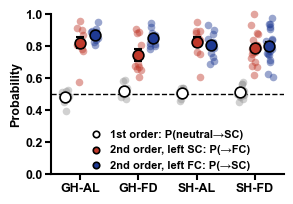

In [12]:
"""
Figure G: first- and second-order transition probabilities per treatment.
Styled to match panels C-E (Arial Bold, large ticks/labels, big markers).

Reuses helpers from the notebook cell that generates second_order_transitions.pdf
(assign_state, collapse_changepoints, two_step_through_neutral, load_master_sheet,
match_treatment). Paste this into that cell or import them.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------- STYLE: tweak these to match C-E ----------------
FONT_SIZE      = 9     # tick labels / axis labels (same as other panels)
ANNOT_SIZE     = 9
INDIV_MS       = 30     # per-animal scatter size
MEAN_MS        = 60     # group mean marker size
ERR_LW        = 1.5
CAPSIZE       = 3
AXIS_LW        = 1.5
FIGSIZE       = (7.62 / 2.54, 5.08 / 2.54)   # EXACT panel size: 7.62 x 5.08 cm
GROUP_ORDER    = ["GH AL", "GH FD", "SH AL", "SH FD"]

plt.rcParams.update({
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.family": ["Arial", "Liberation Sans", "DejaVu Sans"], "font.size": FONT_SIZE, "font.weight": "bold",
    "axes.labelweight": "bold", "axes.titleweight": "bold",
    "axes.linewidth": AXIS_LW,
})

COLORS = {"first": "#FFFFFF", "sc": "#C0392B", "fc": "#1F3A93"}  # white / red / blue


# ---------------- per-animal probabilities ----------------
def first_order_neutral(seq):
    """Counts of Neutral->SC and Neutral->FC in a collapsed state sequence."""
    sc = fc = 0
    for a, b in zip(seq[:-1], seq[1:]):
        if a == "Neutral":
            sc += b == "SC"
            fc += b == "FC"
    return sc, fc


def per_animal_probs(csv_path, assign_state, collapse_changepoints, two_step_through_neutral):
    df = pd.read_csv(csv_path, low_memory=False)
    if "in_SC" not in df.columns or "in_FC" not in df.columns:
        return None
    seq = collapse_changepoints(assign_state(df))
    p = two_step_through_neutral(seq)
    n_sc, n_fc = first_order_neutral(seq)

    def frac(num, den):
        return num / den if den > 0 else np.nan

    return {
        "first": frac(n_sc, n_sc + n_fc),                                        # P(neutral -> SC)
        "sc":    frac(p.get(("SC", "FC"), 0), p.get(("SC", "FC"), 0) + p.get(("SC", "SC"), 0)),  # left SC: P(->FC)
        "fc":    frac(p.get(("FC", "SC"), 0), p.get(("FC", "SC"), 0) + p.get(("FC", "FC"), 0)),  # left FC: P(->SC)
    }


# ---------------- plotting ----------------
def plot_figure_g(animal_df, group_order=GROUP_ORDER, out="figure_G.pdf"):
    """animal_df columns: Treatment, first, sc, fc  (one row per animal)."""
    fig = plt.figure(figsize=FIGSIZE)
    # fixed margins in inches -> the file is exactly FIGSIZE (do NOT use bbox_inches="tight")
    L, R, B, T = 0.62, 0.05, 0.32, 0.08
    W, H = FIGSIZE
    ax = fig.add_axes([L / W, B / H, (W - L - R) / W, (H - B - T) / H])
    offsets = {"first": -0.25, "sc": 0.0, "fc": 0.25}
    rng = np.random.default_rng(0)

    for gi, g in enumerate(group_order):
        sub = animal_df[animal_df["Treatment"] == g]
        for key, off in offsets.items():
            vals = sub[key].dropna().values
            if len(vals) == 0:
                continue
            x = gi + off
            ax.scatter(x + rng.uniform(-0.06, 0.06, len(vals)), vals,
                       s=INDIV_MS, color=COLORS[key] if key != "first" else "0.6",
                       alpha=0.45, linewidths=0, zorder=2, clip_on=False)
            m = vals.mean()
            sem = vals.std(ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0
            ax.errorbar(x, m, yerr=sem, fmt="none", ecolor="black",
                        elinewidth=ERR_LW, capsize=CAPSIZE, capthick=ERR_LW, zorder=3)
            ax.scatter(x, m, s=MEAN_MS, color=COLORS[key], edgecolor="black",
                       linewidths=1.2, zorder=4, clip_on=False)

    ax.axhline(0.5, color="black", ls="--", lw=1.0, zorder=1)

    # y axis: spans exactly 0 -> 1.0 and ends there (points at 1.0 are not clipped)
    ax.set_ylim(0, 1.0)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.spines["left"].set_bounds(0, 1.0)
    ax.set_ylabel("Probability", fontsize=FONT_SIZE, fontweight="bold", labelpad=2)

    ax.set_xlim(-0.5, len(group_order) - 0.5)
    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels([g.replace(" ", "-") for g in group_order],
                       fontsize=FONT_SIZE, fontweight="bold")
    ax.tick_params(axis="both", width=AXIS_LW, length=4, labelsize=FONT_SIZE, pad=2)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)

    handles = [
        ax.scatter([], [], s=MEAN_MS, color=COLORS["first"], edgecolor="black", linewidths=1.2,
                   label="1st order: P(neutral→SC)"),
        ax.scatter([], [], s=MEAN_MS, color=COLORS["sc"], edgecolor="black", linewidths=1.2,
                   label="2nd order, left SC: P(→FC)"),
        ax.scatter([], [], s=MEAN_MS, color=COLORS["fc"], edgecolor="black", linewidths=1.2,
                   label="2nd order, left FC: P(→SC)"),
    ]
    ax.legend(handles=handles, fontsize=8, frameon=False, loc="lower center",
              bbox_to_anchor=(0.5, -0.02), handletextpad=0.3, labelspacing=0.5,
              borderpad=0.1, markerscale=0.6)   # smaller legend dots, more row spacing

    fig.savefig(out)          # no bbox_inches="tight" -> stays 7.62 x 5.08 cm
    return fig, ax


# ---------------- usage inside your existing main() ----------------
# rows = []
# for csv_path in csv_paths:
#     info = match_treatment(csv_path, treatment_map)
#     if info is None: continue
#     r = per_animal_probs(csv_path, assign_state, collapse_changepoints, two_step_through_neutral)
#     if r: rows.append({"Treatment": info["Treatment"], **r})
# plot_figure_g(pd.DataFrame(rows))

if __name__ == "__main__":      # synthetic smoke test
    rng = np.random.default_rng(1)
    rows = []
    for g, n in zip(GROUP_ORDER, (10, 10, 11, 18)):
        for _ in range(n):
            rows.append({"Treatment": g,
                         "first": np.clip(rng.normal(.5, .04), 0, 1),
                         "sc": np.clip(rng.normal(.8, .12), 0, 1),
                         "fc": np.clip(rng.normal(.85, .1), 0, 1)})
    plot_figure_g(pd.DataFrame(rows), out="figure_G_test.pdf")